# ANCP T## — D3 Exploratory Data Analysis (EDA)
## IndiGo EBITDA Margin and macro-market indicators **Dataset used:** `EDA ANALYSIS(5).xlsx` — `Sheet1` **Observation level:** 38 quarterly observations **Primary and only profitability outcome:** EBITDA Margin This notebook follows the same broad EDA workflow as the supplied EDA notebook, adapted to the new quarterly dataset. The analysis focuses exclusively on EBITDA Margin and its relationship with USD/INR, CPI, WPI, and the supplied oil benchmark indicators. **Business question:** How are IndiGo's quarterly EBITDA margins associated with the supplied macroeconomic and oil-market indicators, and what does the evidence imply for next-quarter EBITDA-margin modelling? > Associations are exploratory and do not establish causation. The workbook does not identify the exact oil benchmark or units, so the oil variables are treated as supplied benchmark proxies.

## 1. Business question and analytical objectives
The analysis will:
1. assess the structure, completeness, consistency, and coverage of the quarterly dataset;
2. examine the distribution and descriptive statistics of EBITDA Margin and macro-market indicators;
3. examine EBITDA Margin trends over time;
4. explore relationships between EBITDA Margin and macro/market indicators;
5. compare calendar-quarter patterns;
6. test pre-defined exploratory hypotheses;
7. record evidence-based insights and implications for the next-quarter EBITDA-margin model.

The dataset does not include passenger load factor, passenger yield, capacity, revenue, fuel consumption, or explicit source metadata. These omissions limit the business explanations that can be supported.

## 2. Hypotheses defined before viewing analytical results
- **H1:** EBITDA Margin is associated with USD/INR.
- **H2:** EBITDA Margin is associated with the monthly oil benchmark proxy.
- **H3:** EBITDA Margin is negatively associated with CPI inflation.
- **H4:** EBITDA Margin is negatively associated with WPI inflation.
- **H5:** EBITDA Margin differs across calendar quarters.

These are exploratory hypotheses. Statistical significance should be interpreted cautiously because the dataset contains only 38 quarterly observations and time-series observations may not be independent.

## 3. Imports, configuration, and reproducibility

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_FILE = Path("EDA ANALYSIS(5).xlsx")
if not DATA_FILE.exists():
    candidates = [Path("/content/EDA ANALYSIS(5).xlsx"),
                  Path("/mnt/data/EDA ANALYSIS(5).xlsx")]
    DATA_FILE = next((p for p in candidates if p.exists()), None)

if DATA_FILE is None:
    raise FileNotFoundError(
        "Upload 'EDA ANALYSIS(5).xlsx' to the notebook working directory "
        "or update DATA_FILE with its correct path."
    )

print("Dataset path:", DATA_FILE.resolve())

Dataset path: /mnt/data/EDA ANALYSIS(5).xlsx


## 4. Dataset loading and initial inspection

In [2]:
# Load only the fields required for the EBITDA-focused analysis.
required_columns = [
    "Year", "Quarter (Calendar)", "EBITDA Margin",
    "USD INR (Quarterly Mean)", "CPI inflation (Quarterly Mean)",
    "WPI inflation (Quarterly Mean)",
    "Oil benchmark(DAILY) (Quarterly Mean)",
    "Oil benchmark(MONTHLY) (Quarterly Mean)"
]
raw_all = pd.read_excel(DATA_FILE, sheet_name="Sheet1")
missing_required = [c for c in required_columns if c not in raw_all.columns]
if missing_required:
    raise ValueError(f"Required columns missing from workbook: {missing_required}")
raw = raw_all[required_columns].copy()
df = raw.copy()

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())
print("\nFirst five rows:")
display(df.head())
print("\nLast five rows:")
display(df.tail())
print("\nDescriptive overview:")
display(df.describe(include="all").T)

Dataset shape: (38, 8)

Column names:
['Year', 'Quarter (Calendar)', 'EBITDA Margin', 'USD INR (Quarterly Mean)', 'CPI inflation (Quarterly Mean)', 'WPI inflation (Quarterly Mean)', 'Oil benchmark(DAILY) (Quarterly Mean)', 'Oil benchmark(MONTHLY) (Quarterly Mean)']

Data types:


,data_type
Year,int64
Quarter (Calendar),object
EBITDA Margin,float64
USD INR (Quarterly Mean),float64
CPI inflation (Quarterly Mean),float64
WPI inflation (Quarterly Mean),float64
Oil benchmark(DAILY) (Quarterly Mean),float64
Oil benchmark(MONTHLY) (Quarterly Mean),float64



First five rows:


,Year,Quarter (Calendar),EBITDA Margin,USD INR (Quarterly Mean),CPI inflation (Quarterly Mean),WPI inflation (Quarterly Mean),Oil benchmark(DAILY) (Quarterly Mean),Oil benchmark(MONTHLY) (Quarterly Mean)
0,2017,Q1,15.000,66.468,3.570,4.960,53.690,53.707
1,2017,Q2,15.000,64.445,2.210,2.337,49.763,49.273
2,2017,Q3,10.478,64.457,2.973,2.753,52.699,54.470
3,2017,Q4,19.069,64.359,4.557,3.760,61.640,64.060
4,2018,Q1,13.951,64.647,4.597,2.833,66.797,67.537



Last five rows:


,Year,Quarter (Calendar),EBITDA Margin,USD INR (Quarterly Mean),CPI inflation (Quarterly Mean),WPI inflation (Quarterly Mean),Oil benchmark(DAILY) (Quarterly Mean),Oil benchmark(MONTHLY) (Quarterly Mean)
33,2025,Q2,29.933,85.276,2.893,0.000,67.860,65.023
34,2025,Q3,26.836,88.198,1.680,-0.330,69.090,69.395
35,2025,Q4,26.113,89.368,0.567,-0.490,63.692,64.000
36,2026,Q1,18.594,92.600,3.117,2.450,81.040,90.172
37,2026,Q2,27.563,94.864,3.930,9.403,103.771,95.823



Descriptive overview:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Year,38.000,NaN,NaN,NaN,"2,021.263",2.787,"2,017.000","2,019.000","2,021.000","2,023.750","2,026.000"
Quarter (Calendar),38,4,Q1,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EBITDA Margin,38.000,NaN,NaN,NaN,12.306,14.255,-36.667,7.546,15.000,22.229,29.933
USD INR (Quarterly Mean),38.000,NaN,NaN,NaN,76.961,8.239,64.359,70.784,75.022,83.245,94.864
CPI inflation (Quarterly Mean),38.000,NaN,NaN,NaN,4.637,1.639,0.567,3.497,4.830,6.052,7.280
WPI inflation (Quarterly Mean),38.000,NaN,NaN,NaN,3.977,4.774,-2.860,0.946,2.567,5.018,16.080
Oil benchmark(DAILY) (Quarterly Mean),38.000,NaN,NaN,NaN,71.890,17.478,29.998,62.434,71.192,81.132,113.888
Oil benchmark(MONTHLY) (Quarterly Mean),38.000,NaN,NaN,NaN,71.902,17.660,32.108,62.490,72.386,82.230,117.598


## 5. Original-data quality assessment

In [3]:
def audit_frame(frame, name):
    return {
        "dataset": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "duplicate_rows": int(frame.duplicated().sum()),
        "missing_cells": int(frame.isna().sum().sum()),
        "missing_pct": round(frame.isna().sum().sum() / max(frame.size, 1) * 100, 2),
    }

display(pd.DataFrame([audit_frame(raw, "EDA ANALYSIS(5).xlsx — Sheet1")]))
display(pd.DataFrame({
    "column": raw.columns,
    "dtype": [str(raw[c].dtype) for c in raw.columns],
    "missing_count": [int(raw[c].isna().sum()) for c in raw.columns],
    "unique_values": [int(raw[c].nunique(dropna=True)) for c in raw.columns],
}))

,dataset,rows,columns,duplicate_rows,missing_cells,missing_pct
0,EDA ANALYSIS(5).xlsx — Sheet1,38,8,0,0,0.000


,column,dtype,missing_count,unique_values
0,Year,int64,0,10
1,Quarter (Calendar),object,0,4
2,EBITDA Margin,float64,0,37
3,USD INR (Quarterly Mean),float64,0,38
4,CPI inflation (Quarterly Mean),float64,0,38
5,WPI inflation (Quarterly Mean),float64,0,38
6,Oil benchmark(DAILY) (Quarterly Mean),float64,0,38
7,Oil benchmark(MONTHLY) (Quarterly Mean),float64,0,38


## 6. Original-data representativeness and bias checks

In [4]:
print("Year coverage:")
display(df.groupby("Year").size().rename("quarterly_rows").to_frame())

print("Calendar-quarter coverage:")
display(df["Quarter (Calendar)"].value_counts(dropna=False).sort_index().rename("rows").to_frame())

print("Year and quarter combinations:")
display(df[["Year", "Quarter (Calendar)"]].head(12))

print("Potential duplicate year-quarter combinations:",
      int(df.duplicated(["Year", "Quarter (Calendar)"]).sum()))

Year coverage:


,quarterly_rows
Year,
2017,4
2018,4
2019,4
2020,4
2021,4
2022,4
2023,4
2024,4
2025,4


Calendar-quarter coverage:


,rows
Quarter (Calendar),
Q1,10
Q2,10
Q3,9
Q4,9


Year and quarter combinations:


,Year,Quarter (Calendar)
0,2017,Q1
1,2017,Q2
2,2017,Q3
3,2017,Q4
4,2018,Q1
5,2018,Q2
6,2018,Q3
7,2018,Q4
8,2019,Q1
9,2019,Q2


Potential duplicate year-quarter combinations: 0


## 7. Documented cleaning and transformation

In [5]:
cleaning_log = []

def log_cleaning(action, reason, impact):
    cleaning_log.append({
        "dataset": DATA_FILE.name,
        "action": action,
        "reason": reason,
        "impact": impact
    })

panel = raw.copy()

# Standardize column names only for easier, consistent analysis.
column_map = {
    "Quarter (Calendar)": "calendar_quarter",
    "EBITDA Margin": "ebitda_margin_pct",
    "USD INR (Quarterly Mean)": "usd_inr",
    "CPI inflation (Quarterly Mean)": "cpi_inflation",
    "WPI inflation (Quarterly Mean)": "wpi_inflation",
    "Oil benchmark(DAILY) (Quarterly Mean)": "oil_daily_mean",
    "Oil benchmark(MONTHLY) (Quarterly Mean)": "oil_monthly_mean",
}
panel = panel.rename(columns=column_map)
log_cleaning("Standardized column names",
             "Create consistent analysis-friendly variable names",
             "Column labels changed; underlying values retained")

numeric_cols = [
    "Year", "ebitda_margin_pct", "usd_inr",
    "cpi_inflation", "wpi_inflation", "oil_daily_mean", "oil_monthly_mean"
]
for col in numeric_cols:
    before_missing = int(panel[col].isna().sum())
    panel[col] = pd.to_numeric(panel[col], errors="coerce")
    after_missing = int(panel[col].isna().sum())
    if after_missing > before_missing:
        log_cleaning(f"Numeric conversion: {col}",
                     "Convert values to numeric for statistical analysis",
                     f"{after_missing-before_missing} additional missing value(s) created")

quarter_order = {"Q1": 1, "Q2": 2, "Q3": 3, "Q4": 4}
panel["quarter_num"] = panel["calendar_quarter"].astype(str).str.upper().map(quarter_order)
panel["quarter_end"] = pd.to_datetime(
    panel["Year"].astype("Int64").astype(str) + "-" +
    panel["quarter_num"].map({1:"03-31", 2:"06-30", 3:"09-30", 4:"12-31"}),
    errors="coerce"
)
log_cleaning("Created quarter-end date",
             "Convert Year and calendar quarter into a sortable date",
             "Added quarter_end and quarter_num fields")

panel = panel.sort_values("quarter_end").reset_index(drop=True)
log_cleaning("Chronological sorting",
             "Make time-based patterns and lag order readable",
             "Rows reordered chronologically; observations retained")

# No automatic outlier removal, winsorization, or missing-value imputation.
log_cleaning("Outlier handling",
             "Retain extreme observations for contextual review",
             "No values removed or capped")
log_cleaning("Missing-value handling",
             "Avoid introducing unsupported assumptions",
             "No imputation performed")

display(pd.DataFrame(cleaning_log))

,dataset,action,reason,impact
0,EDA ANALYSIS(5).xlsx,Standardized column names,Create consistent analysis-friendly variable n...,Column labels changed; underlying values retained
1,EDA ANALYSIS(5).xlsx,Created quarter-end date,Convert Year and calendar quarter into a sorta...,Added quarter_end and quarter_num fields
2,EDA ANALYSIS(5).xlsx,Chronological sorting,Make time-based patterns and lag order readable,Rows reordered chronologically; observations r...
3,EDA ANALYSIS(5).xlsx,Outlier handling,Retain extreme observations for contextual review,No values removed or capped
4,EDA ANALYSIS(5).xlsx,Missing-value handling,Avoid introducing unsupported assumptions,No imputation performed


## 8. Cleaned-data quality checks

In [6]:
display(pd.DataFrame([audit_frame(panel, "Quarterly analysis panel")]))
display(pd.DataFrame({
    "variable": panel.columns,
    "dtype": [str(panel[c].dtype) for c in panel.columns],
    "missing_count": [int(panel[c].isna().sum()) for c in panel.columns],
    "unique_values": [int(panel[c].nunique(dropna=True)) for c in panel.columns],
}))
print("Chronological order check:",
      bool(panel["quarter_end"].is_monotonic_increasing))
print("Duplicate quarter-end dates:", int(panel["quarter_end"].duplicated().sum()))

,dataset,rows,columns,duplicate_rows,missing_cells,missing_pct
0,Quarterly analysis panel,38,10,0,0,0.000


,variable,dtype,missing_count,unique_values
0,Year,int64,0,10
1,calendar_quarter,object,0,4
2,ebitda_margin_pct,float64,0,37
3,usd_inr,float64,0,38
4,cpi_inflation,float64,0,38
5,wpi_inflation,float64,0,38
6,oil_daily_mean,float64,0,38
7,oil_monthly_mean,float64,0,38
8,quarter_num,int64,0,4
9,quarter_end,datetime64[ns],0,38


Chronological order check: True
Duplicate quarter-end dates: 0


## 9. Repeated representativeness and bias checks on cleaned data

In [7]:
coverage = pd.DataFrame([{
    "dataset": "Quarterly analysis panel",
    "rows": len(panel),
    "start_quarter": panel["quarter_end"].min(),
    "end_quarter": panel["quarter_end"].max(),
    "calendar_quarters_present": panel["calendar_quarter"].nunique(),
    "missing_EBITDA": int(panel["ebitda_margin_pct"].isna().sum()),
}])
display(coverage)

print("Rows per calendar quarter:")
display(panel.groupby("calendar_quarter").size().rename("observations").to_frame())

print("Representativeness notes:")
print("- The dataset contains quarterly observations only.")
print("- The available period and indicators may not represent all drivers of airline profitability.")
print("- There are no operational variables such as load factor, passenger yield, or capacity.")
print("- The oil benchmark definition and units are not specified in the workbook.")

,dataset,rows,start_quarter,end_quarter,calendar_quarters_present,missing_EBITDA
0,Quarterly analysis panel,38,2017-03-31,2026-06-30,4,0


Rows per calendar quarter:


,observations
calendar_quarter,
Q1,10
Q2,10
Q3,9
Q4,9


Representativeness notes:
- The dataset contains quarterly observations only.
- The available period and indicators may not represent all drivers of airline profitability.
- There are no operational variables such as load factor, passenger yield, or capacity.
- The oil benchmark definition and units are not specified in the workbook.


## 10. Distribution analysis

,count,mean,std,min,25%,50%,75%,max
ebitda_margin_pct,38.000,12.306,14.255,-36.667,7.546,15.000,22.229,29.933
usd_inr,38.000,76.961,8.239,64.359,70.784,75.022,83.245,94.864
cpi_inflation,38.000,4.637,1.639,0.567,3.497,4.830,6.052,7.280
wpi_inflation,38.000,3.977,4.774,-2.860,0.946,2.567,5.018,16.080
oil_daily_mean,38.000,71.890,17.478,29.998,62.434,71.192,81.132,113.888
oil_monthly_mean,38.000,71.902,17.660,32.108,62.490,72.386,82.230,117.598


,variable,count,skewness,kurtosis,IQR
0,ebitda_margin_pct,38,-1.482,2.922,14.683
1,usd_inr,38,0.249,-0.786,12.461
2,cpi_inflation,38,-0.395,-0.437,2.554
3,wpi_inflation,38,1.164,0.540,4.072
4,oil_daily_mean,38,0.126,0.417,18.698
5,oil_monthly_mean,38,0.136,0.391,19.740


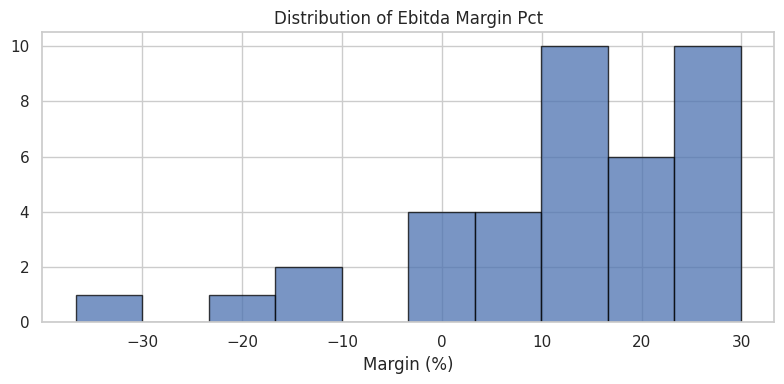

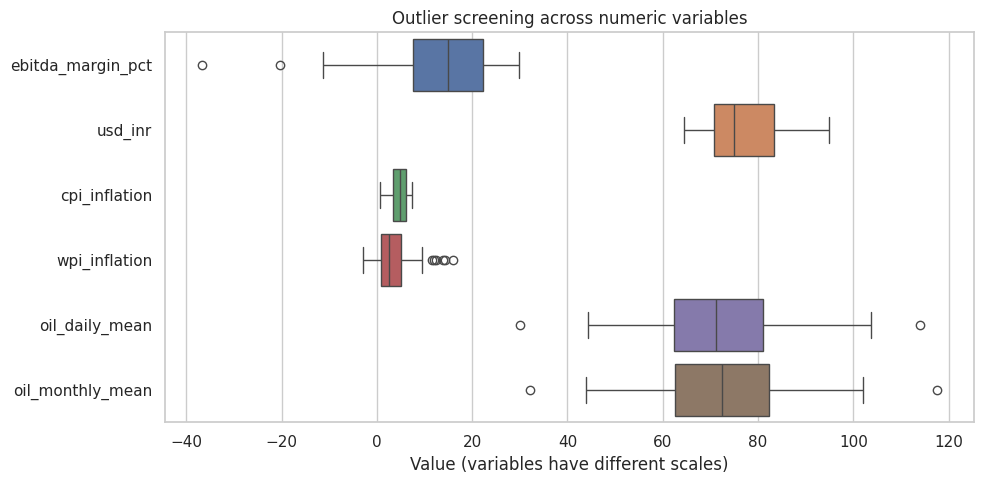

In [8]:
num_cols = [
    "ebitda_margin_pct", "usd_inr",
    "cpi_inflation", "wpi_inflation", "oil_daily_mean", "oil_monthly_mean"
]
display(panel[num_cols].describe().T)

distribution_stats = []
for col in num_cols:
    values = panel[col].dropna()
    distribution_stats.append({
        "variable": col,
        "count": len(values),
        "skewness": values.skew() if len(values) > 2 else np.nan,
        "kurtosis": values.kurtosis() if len(values) > 3 else np.nan,
        "IQR": values.quantile(.75) - values.quantile(.25) if len(values) else np.nan
    })
display(pd.DataFrame(distribution_stats))

for col in ["ebitda_margin_pct"]:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(panel[col].dropna(), bins=10, edgecolor="black", alpha=0.75)
    ax.set_title(f"Distribution of {col.replace('_', ' ').title()}")
    ax.set_xlabel("Margin (%)")
    plt.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=panel[num_cols], orient="h", ax=ax)
ax.set_title("Outlier screening across numeric variables")
ax.set_xlabel("Value (variables have different scales)")
plt.tight_layout()
plt.show()

## 11. Time trends and relationship analysis

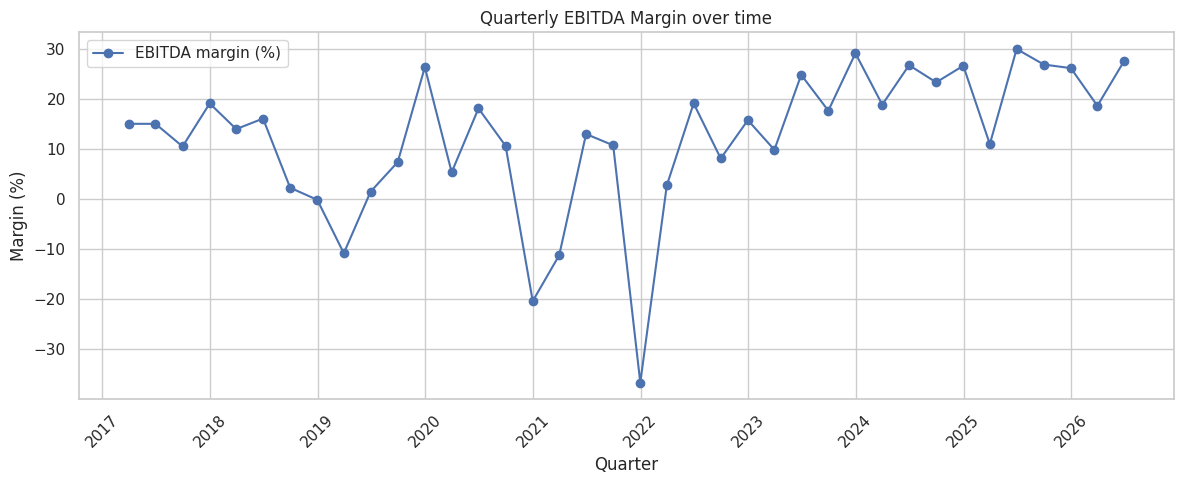

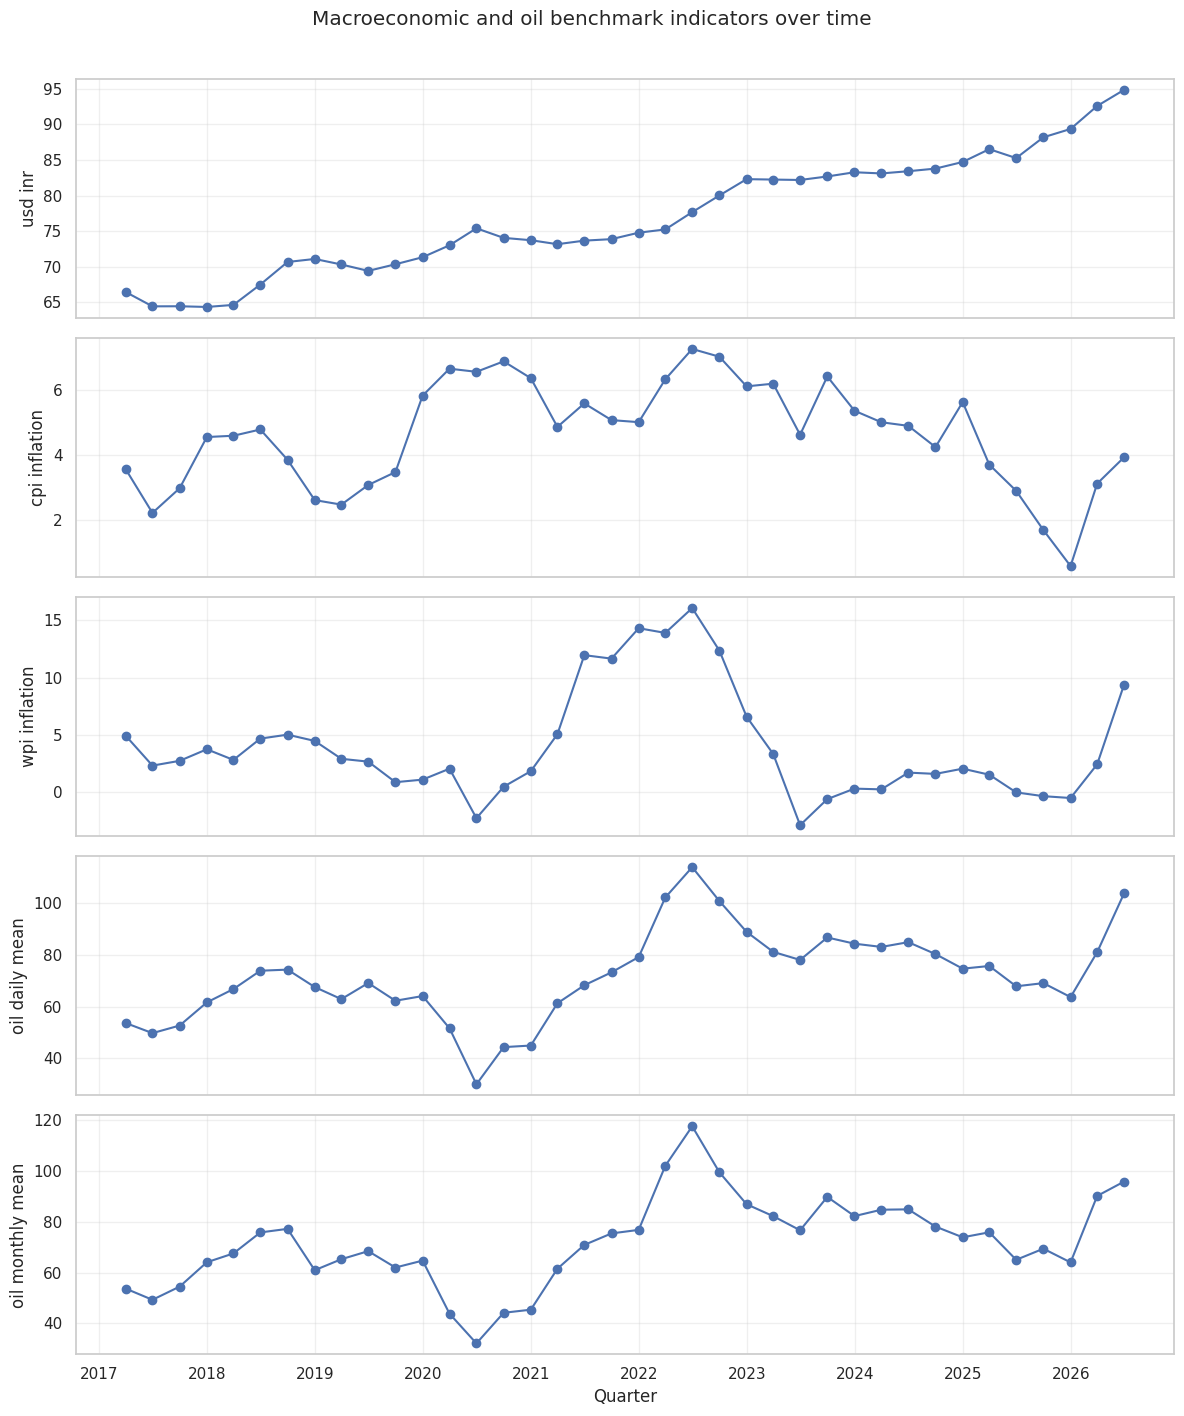

,ebitda_margin_pct,usd_inr,cpi_inflation,wpi_inflation,oil_daily_mean,oil_monthly_mean
ebitda_margin_pct,1.000,0.554,-0.087,-0.450,0.292,0.264
usd_inr,0.554,1.000,0.084,-0.319,0.570,0.527
cpi_inflation,-0.087,0.084,1.000,0.170,0.246,0.238
wpi_inflation,-0.450,-0.319,0.170,1.000,0.275,0.306
oil_daily_mean,0.292,0.570,0.246,0.275,1.000,0.979
oil_monthly_mean,0.264,0.527,0.238,0.306,0.979,1.000


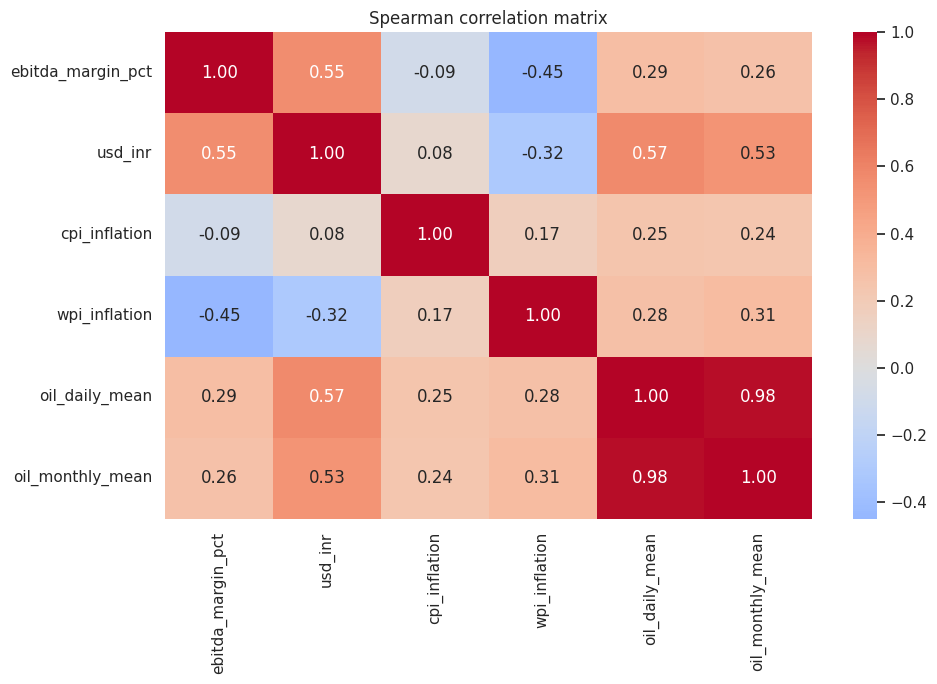

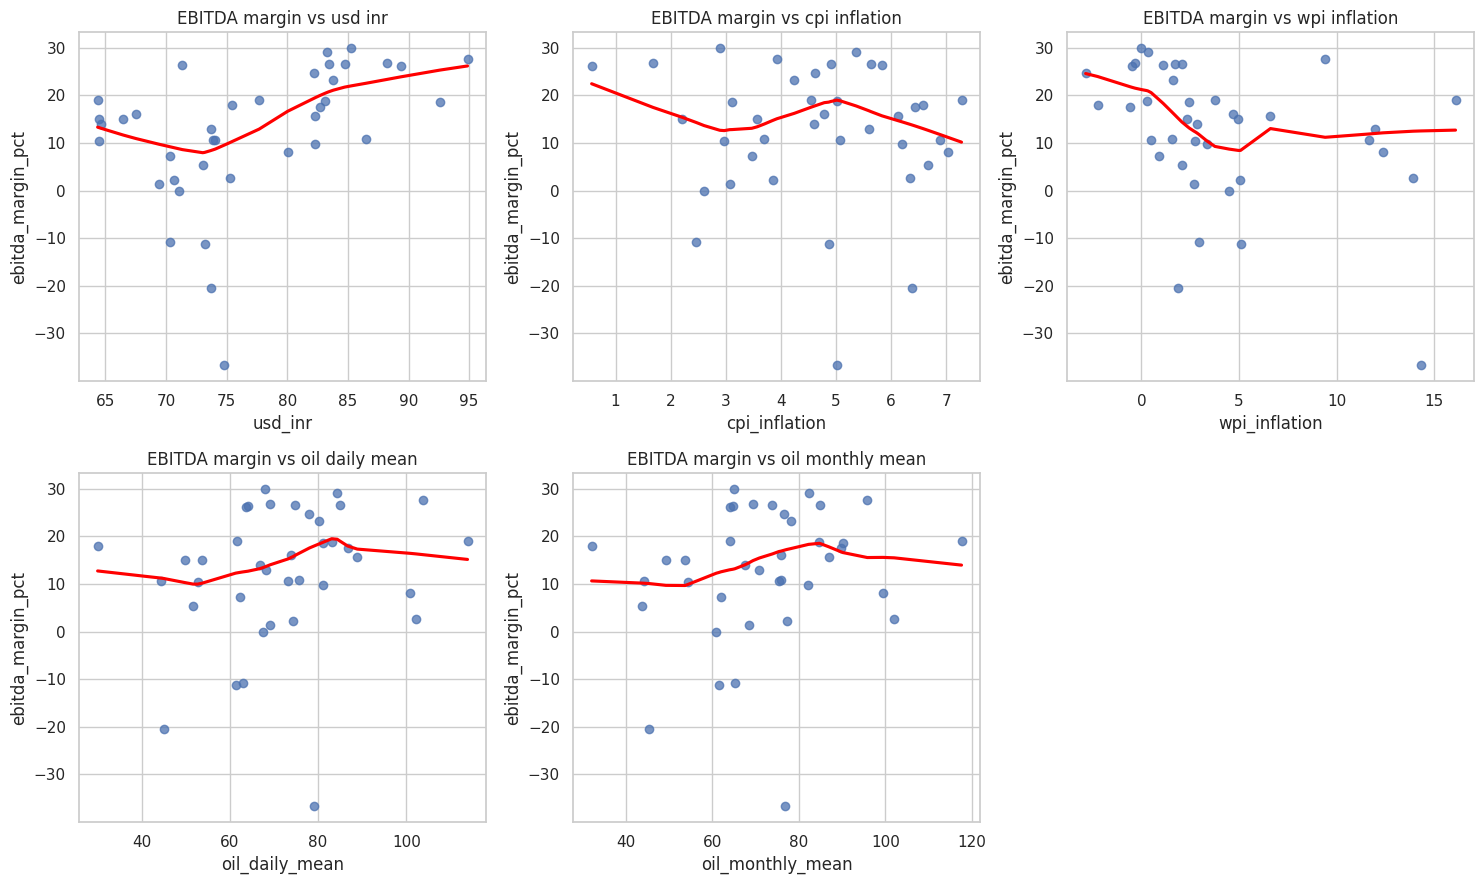

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(panel["quarter_end"], panel["ebitda_margin_pct"], marker="o", label="EBITDA margin (%)")
ax.set_title("Quarterly EBITDA Margin over time")
ax.set_xlabel("Quarter")
ax.set_ylabel("Margin (%)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

macro_cols = ["usd_inr", "cpi_inflation", "wpi_inflation", "oil_daily_mean", "oil_monthly_mean"]
fig, axes = plt.subplots(len(macro_cols), 1, figsize=(12, 14), sharex=True)
for ax, col in zip(axes, macro_cols):
    ax.plot(panel["quarter_end"], panel[col], marker="o")
    ax.set_ylabel(col.replace("_", " "))
    ax.grid(True, alpha=.3)
axes[-1].set_xlabel("Quarter")
fig.suptitle("Macroeconomic and oil benchmark indicators over time", y=1.01)
plt.tight_layout()
plt.show()

corr_cols = ["ebitda_margin_pct"] + macro_cols
corr = panel[corr_cols].corr(method="spearman")
display(corr.round(3))
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=ax)
ax.set_title("Spearman correlation matrix")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, macro_cols):
    sns.regplot(data=panel, x=col, y="ebitda_margin_pct",
                lowess=True, scatter_kws={"alpha":.75}, line_kws={"color":"red"}, ax=ax)
    ax.set_title(f"EBITDA margin vs {col.replace('_', ' ')}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## 12. Segment analysis

,count,mean,median,std,min,max
calendar_quarter,,,,,,
Q1,10,7.314,10.384,10.954,-11.214,18.827
Q2,10,19.161,18.576,8.531,1.462,29.933
Q3,9,13.023,10.590,7.966,2.239,26.836
Q4,9,9.519,19.069,23.672,-36.667,29.082


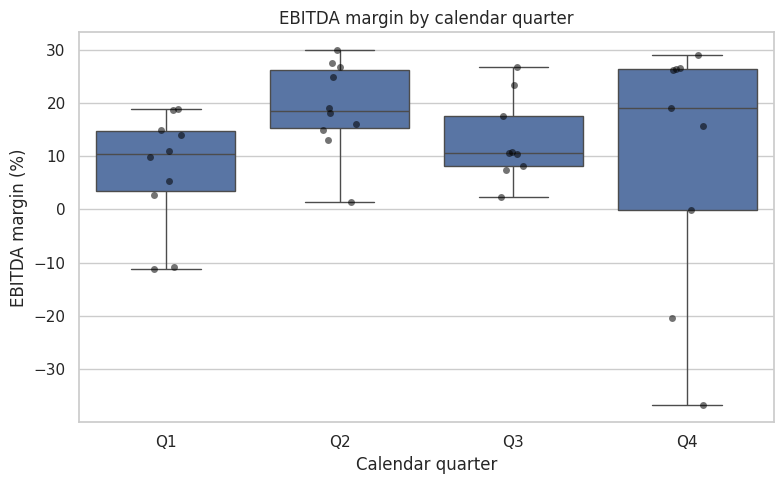

In [10]:
quarter_summary = (
    panel.groupby("calendar_quarter")["ebitda_margin_pct"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reindex(["Q1", "Q2", "Q3", "Q4"])
)
display(quarter_summary)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=panel, x="calendar_quarter", y="ebitda_margin_pct",
            order=["Q1", "Q2", "Q3", "Q4"], ax=ax)
sns.stripplot(data=panel, x="calendar_quarter", y="ebitda_margin_pct",
              order=["Q1", "Q2", "Q3", "Q4"], color="black", alpha=.55, ax=ax)
ax.set_title("EBITDA margin by calendar quarter")
ax.set_xlabel("Calendar quarter")
ax.set_ylabel("EBITDA margin (%)")
plt.tight_layout()
plt.show()



## 13. Hypothesis assessment and statistical tests

In [11]:
hypothesis_results = []

def spearman_test(hid, statement, x, y, expected_direction=None):
    sub = panel[[x, y]].dropna()
    if len(sub) < 5 or sub[x].nunique() < 2 or sub[y].nunique() < 2:
        hypothesis_results.append({
            "ID": hid, "Hypothesis": statement, "n": len(sub),
            "Spearman_rho": np.nan, "p_value": np.nan,
            "Result": "Insufficient usable variation/data"
        })
        return
    rho, p = stats.spearmanr(sub[x], sub[y])
    result = ("Statistically significant exploratory association" if p < .05
              else "No statistically significant association detected")
    if expected_direction and np.sign(rho) != expected_direction:
        result += "; observed direction differs from expectation"
    hypothesis_results.append({
        "ID": hid, "Hypothesis": statement, "n": len(sub),
        "Spearman_rho": rho, "p_value": p, "Result": result
    })

spearman_test("H1", "EBITDA Margin is associated with USD/INR",
              "ebitda_margin_pct", "usd_inr")
spearman_test("H2", "EBITDA Margin is associated with the monthly oil benchmark proxy",
              "ebitda_margin_pct", "oil_monthly_mean")
spearman_test("H3", "EBITDA Margin is negatively associated with CPI inflation",
              "ebitda_margin_pct", "cpi_inflation", expected_direction=-1)
spearman_test("H4", "EBITDA Margin is negatively associated with WPI inflation",
              "ebitda_margin_pct", "wpi_inflation", expected_direction=-1)

# Kruskal-Wallis test compares EBITDA Margin distributions across calendar quarters.
groups = [
    panel.loc[panel["calendar_quarter"] == q, "ebitda_margin_pct"].dropna().values
    for q in ["Q1", "Q2", "Q3", "Q4"]
]
groups = [g for g in groups if len(g) > 0]
if len(groups) >= 2:
    h_stat, p_value = stats.kruskal(*groups)
    hypothesis_results.append({
        "ID": "H5",
        "Hypothesis": "EBITDA Margin differs across calendar quarters",
        "n": int(sum(len(g) for g in groups)),
        "Spearman_rho": np.nan,
        "p_value": p_value,
        "Result": "Quarter-group difference detected" if p_value < .05
                  else "No statistically significant quarter-group difference detected"
    })

hypothesis_table = pd.DataFrame(hypothesis_results)
display(hypothesis_table)
print("Caution: p-values are exploratory; small sample size and time dependence limit inference.")

,ID,Hypothesis,n,Spearman_rho,p_value,Result
0,H1,EBITDA Margin is associated with USD/INR,38,0.554,0.000,Statistically significant exploratory association
1,H2,EBITDA Margin is associated with the monthly o...,38,0.264,0.109,No statistically significant association detected
2,H3,EBITDA Margin is negatively associated with CP...,38,-0.087,0.605,No statistically significant association detected
3,H4,EBITDA Margin is negatively associated with WP...,38,-0.450,0.005,Statistically significant exploratory association
4,H5,EBITDA Margin differs across calendar quarters,38,NaN,0.125,No statistically significant quarter-group dif...


Caution: p-values are exploratory; small sample size and time dependence limit inference.


## 14. Insight log

In [12]:
insights = []

def add_insight(iid, insight, evidence, business, modelling, confidence):
    insights.append({
        "Insight ID": iid,
        "Insight": insight,
        "Evidence": evidence,
        "Business implication": business,
        "Modelling implication": modelling,
        "Confidence": confidence
    })

# Summarize the EBITDA margin distribution directly.
margin_summary = panel["ebitda_margin_pct"].describe()
add_insight(
    "I1",
    f"Average EBITDA margin = {margin_summary['mean']:.3f}% across available quarters.",
    f"Median = {margin_summary['50%']:.3f}%; standard deviation = {margin_summary['std']:.3f} percentage points.",
    "Use the historical range to understand variation in operating profitability.",
    "Compare forecasting models against historical and seasonal-naive benchmarks.",
    "Descriptive evidence"
)

for col, label in [
    ("usd_inr", "USD/INR"),
    ("cpi_inflation", "CPI inflation"),
    ("wpi_inflation", "WPI inflation"),
    ("oil_monthly_mean", "monthly oil benchmark proxy")
]:
    sub = panel[["ebitda_margin_pct", col]].dropna()
    if len(sub) >= 5:
        rho, p = stats.spearmanr(sub["ebitda_margin_pct"], sub[col])
        add_insight(
            f"I{len(insights)+1}",
            f"EBITDA margin has an observed rank association with {label}.",
            f"Spearman rho = {rho:.3f}; p-value = {p:.3f}; n = {len(sub)}.",
            "The indicator may provide context for profitability changes, but the association is not causal.",
            "Retain as a candidate feature for validation; avoid assuming a stable relationship.",
            "Low to medium; small quarterly sample"
        )

display(pd.DataFrame(insights))

,Insight ID,Insight,Evidence,Business implication,Modelling implication,Confidence
0,I1,Average EBITDA margin = 12.306% across availab...,Median = 15.000%; standard deviation = 14.255 ...,Use the historical range to understand variati...,Compare forecasting models against historical ...,Descriptive evidence
1,I2,EBITDA margin has an observed rank association...,Spearman rho = 0.554; p-value = 0.000; n = 38.,The indicator may provide context for profitab...,Retain as a candidate feature for validation; ...,Low to medium; small quarterly sample
2,I3,EBITDA margin has an observed rank association...,Spearman rho = -0.087; p-value = 0.605; n = 38.,The indicator may provide context for profitab...,Retain as a candidate feature for validation; ...,Low to medium; small quarterly sample
3,I4,EBITDA margin has an observed rank association...,Spearman rho = -0.450; p-value = 0.005; n = 38.,The indicator may provide context for profitab...,Retain as a candidate feature for validation; ...,Low to medium; small quarterly sample
4,I5,EBITDA margin has an observed rank association...,Spearman rho = 0.264; p-value = 0.109; n = 38.,The indicator may provide context for profitab...,Retain as a candidate feature for validation; ...,Low to medium; small quarterly sample


## 15. Implications for future modelling

In [13]:
model_recommendations = pd.DataFrame([
    ["Baseline", "Compare every model with a simple historical and seasonal-naive benchmark.", "Prevents complex models from appearing useful without evidence."],
    ["Validation", "Use chronological or expanding-window validation; do not randomly shuffle quarterly observations.", "Preserves time order and reduces look-ahead risk."],
    ["Features", "Evaluate USD/INR, CPI, WPI, and both supplied oil benchmark series as candidate predictors.", "Use only variables available at the forecast date."],
    ["Small sample", "Prefer parsimonious models and report uncertainty.", "Only 38 quarterly observations are available."],
    ["Leakage control", "Any lagged or rolling features must use information available at the forecast origin.", "Prevents future information entering model training."],
    ["Further data", "Add operational drivers such as load factor, passenger yield, capacity, and fuel cost if reliable data becomes available.", "Current workbook omits important airline operating drivers."]
], columns=["Area", "Recommendation", "Reason"])
display(model_recommendations)

,Area,Recommendation,Reason
0,Baseline,Compare every model with a simple historical a...,Prevents complex models from appearing useful ...
1,Validation,Use chronological or expanding-window validati...,Preserves time order and reduces look-ahead risk.
2,Features,"Evaluate USD/INR, CPI, WPI, and both supplied ...",Use only variables available at the forecast d...
3,Small sample,Prefer parsimonious models and report uncertai...,Only 38 quarterly observations are available.
4,Leakage control,Any lagged or rolling features must use inform...,Prevents future information entering model tra...
5,Further data,"Add operational drivers such as load factor, p...",Current workbook omits important airline opera...


## 16. Limitations and uncertainty

- The dataset contains only 38 quarterly observations, limiting statistical power and machine-learning reliability.
- The workbook is already quarterly aggregated; the original daily/monthly source records are not available here for independent aggregation checks.
- The exact oil benchmark, source, and units are not specified. It should not automatically be interpreted as IndiGo's actual aviation turbine fuel cost.
- The dataset does not include passenger demand, load factor, passenger yield, capacity, revenue, or route mix.
- Correlation and statistical tests identify associations, not causal effects.
- Quarterly observations may be serially dependent, which can affect conventional statistical test assumptions.
- No missing-value imputation or outlier removal is performed; analyses use available observations.
- The analysis depends on the accuracy and definitions of the supplied workbook fields.

## 17. Conclusions and next steps

In [14]:
print("FINAL EDA CHECKLIST")
print("Dataset:", DATA_FILE.name)
print("Rows:", len(panel))
print("Columns after transformation:", panel.shape[1])
print("Quarterly EBITDA observations:", int(panel["ebitda_margin_pct"].notna().sum()))
print("Quarter span:", panel["quarter_end"].min(), "to", panel["quarter_end"].max())
print("Duplicate year-quarter combinations:", int(panel.duplicated(["Year", "calendar_quarter"]).sum()))
print("Missing values by variable:")
display(panel.isna().sum().rename("missing_count").to_frame())

FINAL EDA CHECKLIST
Dataset: EDA ANALYSIS(5).xlsx
Rows: 38
Columns after transformation: 10
Quarterly EBITDA observations: 38
Quarter span: 2017-03-31 00:00:00 to 2026-06-30 00:00:00
Duplicate year-quarter combinations: 0
Missing values by variable:


,missing_count
Year,0
calendar_quarter,0
ebitda_margin_pct,0
usd_inr,0
cpi_inflation,0
wpi_inflation,0
oil_daily_mean,0
oil_monthly_mean,0
quarter_num,0
quarter_end,0


### Conclusion
This EDA applies the same broad analytical workflow as the supplied notebook to the new quarterly dataset. It examines the quality and coverage of 38 quarterly observations, describes EBITDA Margin and macro-market variables, explores time trends and calendar-quarter patterns, and tests exploratory relationships. The findings provide a starting point for next-quarter EBITDA Margin modelling, subject to the small sample size and data limitations documented above.